Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [1006]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import json
from ipywidgets import interactive
import math

import matplotlib.animation
from IPython.display import HTML

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [1007]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Base scenario

In [897]:
base_parameter_file = "Components/Setup/model_parameters.json"

In [898]:
# Example crop repartition
base_crops = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [899]:
# Initialize System and Model
base_system = SimpleSquareExample(base_parameter_file, boundary_condition="Constant Head")
base_model = IrrigationSchedulingModel(base_parameter_file, boundary_condition="Constant Head")
base_cost_model = IrrigationSchedulingCost(base_parameter_file, base_model, base_crops)

In [900]:
# Simulate constant 
with open("Components/Setup/simple_demand.json", 'r') as file:
    params = json.load(file)
    base_cost_model.yield_sensitivity = 1e3*np.array(params['costs']['yield_sensitivity'])  # [n_crops, n_agent]
    base_cost_model.ET0 = params['physical']['ET0']
    # Time-varying utility data
    base_cost_model._construct_crop_yield_data(params['crops'])
    base_cost_model._construct_evapotranspiration_data(params['crops'])
    base_cost_model._construct_available_water(params['rain'])

In [901]:
base_cost_model._compute_under_irrigation_cost_matrices(0,1)

In [902]:
base_cost_model.Ri_v[v][0]

array([[1.28999748e-05, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 1.20937264e-06, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.16049383e-06, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 3.91203704e-05]])

In [903]:
base_cost_model.Li_v[v][0]

array([[0.08126984, 0.00761905, 0.01422222, 0.14083333]])

In [743]:
base_model.A.toarray().shape

(100, 100)

In [744]:
n_well_per_player = [el.shape[0] for el in base_model.n_well_per_command]
n_well = sum(n_well_per_player)

In [702]:
alpha_w0 = 0.5
alpha_w1 = 0.1
irrigation_repartition = [[alpha_w0, 1-alpha_w0], [alpha_w1, 1-alpha_w1], [1.]]

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3863893131.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


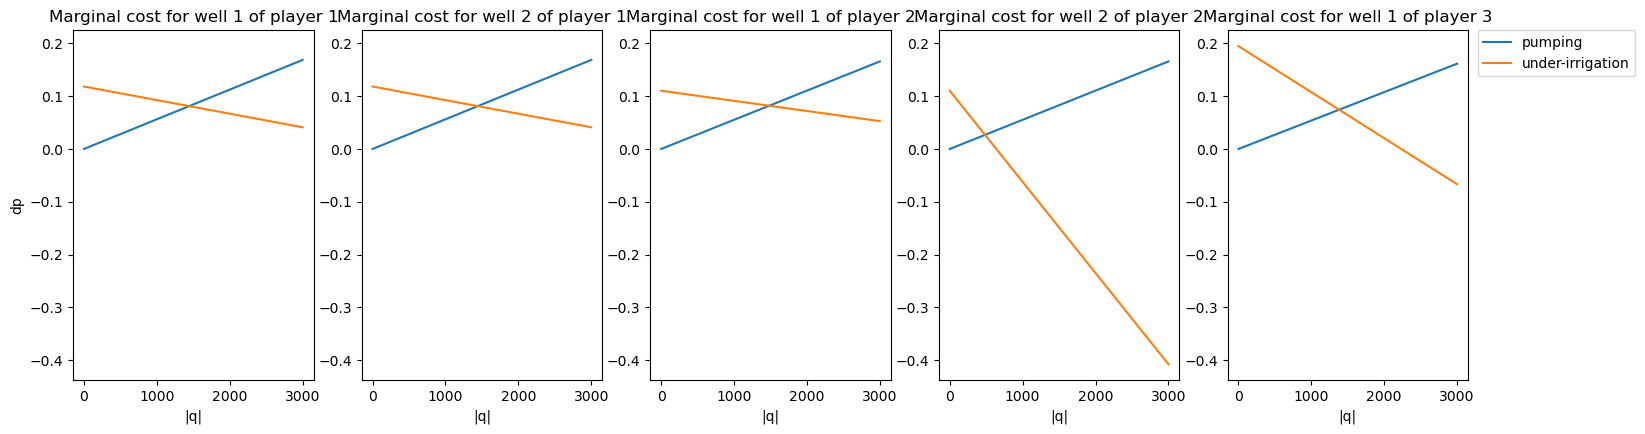

In [464]:
dq = np.linspace(1, 3000, 100)
# Plot marginal cost
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
    i = w - np.cumsum([0]+n_well_per_player)[v]
    ax = fig.add_subplot(2, n_well, w+1, sharey=ax)
    ttl = f"Marginal cost for well {i+1} of player {v+1}"
    ax.set_title(ttl)
    ax.set_xlabel("|q|")
    if w == 0:
        ax.set_ylabel("dp")
    ax.plot(dq, 2*base_cost_model.Rp_v[v][i*4:(i+1)*4, i*4:(i+1)*4].sum()*dq - (base_cost_model.Lp_v[v][:,i*4:(i+1)*4].sum() + 10* base_cost_model.Mp_v[v][:,i*4:(i+1)*4].sum()), label='pumping')
    ax.plot(dq, -(2*irrigation_repartition[v][i]*base_cost_model.Ri_v[v][0].sum()*dq - base_cost_model.Li_v[v][0][:,i*4:(i+1)*4].sum()), label='under-irrigation')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

##### Steady-state system :

$x_s = Ax_s + B^v u_s^v +  B^{-v} u_s^{-v} + C$ and  $J^v(x_s,u_s^v) = {u_s^v}^T R^v u_s^v + {u_s^{-v}}^T R^{-v} u_s^v + x_s^T M^v u_s^v + L^v u_s^v$
<!-- 
So with $\tilde X_s^1 = [x_s^T \ {u_s^1}^T]^T$ and $\tilde X_s^v = u_s^v \ \forall v\ge 2$ , it yields that:

$J^1(\tilde X_s^1, \tilde X_s^v) = {\tilde X_s^1}^T \begin{bmatrix} 0 & M^1 \\ 0 & R^1 \end{bmatrix} \tilde X_s^1 + {\tilde X_s^v}^T \begin{bmatrix} 0 & R^{-1} \end{bmatrix} \tilde X_s^1 + [0 \ L^1] \tilde X_s^1$,

$J^v(\tilde X_s^1, \tilde X_s^v) = {\tilde X_s^v}^T R^v \tilde X_s^v + {\tilde X_s^1}^T \begin{bmatrix} M^v \\ R^{-v} \end{bmatrix} \tilde X_s^v + L^v \tilde X_s^v \forall v\ge 2$ -->

$J^v(u_s^v) = {u_s^v}^T ({B^v}^T{(I-A)^{-1}}^T M^v + R^v) u_s^v + {u_s^{-v}}^T ({B^{-v}}^T{(I-A)^{-1}}^T M^v + R^{-v}) u_s^v + (C^T M^v + L^v) u_s^v$

In [888]:
I_A_inv = np.linalg.inv(np.eye(base_model.A.shape[0]) - base_model.A)

In [904]:
B_minus_v = [sp.hstack([base_model.B_v[mv] for mv in range(base_model.n_agent) if mv !=v]) for v in range(base_model.n_agent)]

In [905]:
A_aggr = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0]),
                              axis=0) for v in range(base_model.n_agent)])
B_aggr = np.hstack([(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v] + base_cost_model.Li_v[v][0]) for v in range(base_model.n_agent)])
U_opt = - np.linalg.pinv(A_aggr + A_aggr.T) @ B_aggr.T
U_opt.T

array([[-5236.07141598,  4958.73634139, -2986.07141598,  4958.73634139, -5263.92858402,  4930.87917335, -3013.92858402,  4930.87917335, -1421.6690264 ,  -371.6690264 ,  1770.11681839,  1770.11681839, -1378.3309736 ,  -328.3309736 ,  1813.45487119,  1813.45487119, -2604.34894874,  2670.27788008,   -22.85285201, -1620.0711101 ]])

Some positive value -> unfeasible solution

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/477733694.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


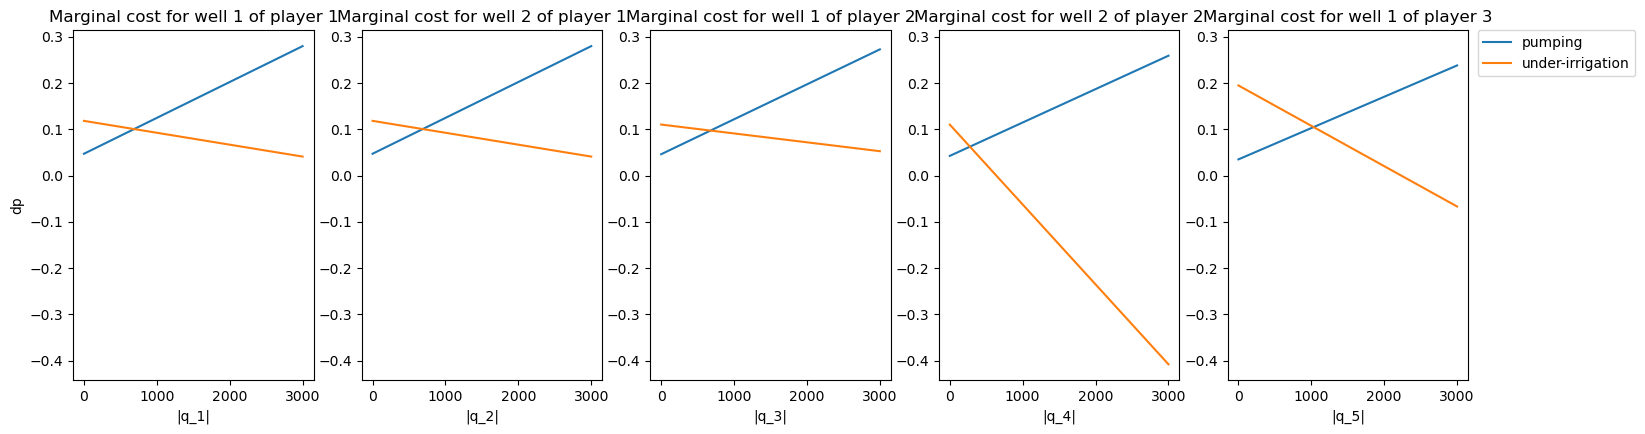

In [469]:
alpha_w0 = 0.5
alpha_w1 = 0.1
irrigation_repartition = [[alpha_w0, 1-alpha_w0], [alpha_w1, 1-alpha_w1], [1.]]

dq = np.linspace(1, 3000, 100)
# Plot marginal cost
fig = plt.figure(figsize=(15+3,10))
ax = None
for w in range(n_well):
    v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
    i = w - np.cumsum([0]+n_well_per_player)[v]
    ax = fig.add_subplot(2, n_well, w+1, sharey=ax)
    ttl = f"Marginal cost for well {i+1} of player {v+1}"
    ax.set_title(ttl)
    ax.set_xlabel(f"|q_{w+1}|")
    if w == 0:
        ax.set_ylabel("dp")
    
    slope_p = 2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, i*4:(i+1)*4].sum()
    offset_p = (base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v])[:,i*4:(i+1)*4].sum()
    
    slope_i = 2*irrigation_repartition[v][i]*(base_cost_model.Ri_v[v][0]).sum()
    offset_i = (base_cost_model.Li_v[v][0])[:,i*4:(i+1)*4].sum()
    
    ax.plot(dq, slope_p*dq - offset_p, label='pumping')
    ax.plot(dq, -(slope_i*dq - offset_i), label='under-irrigation')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [15]:
from ipywidgets import interactive

In [17]:
%%html
<style>
/*overwrite hard coded write background by vscode for ipywidges */
.cell-output-ipywidget-background {
   background-color: transparent !important;
}

/*set widget foreground text and color of interactive widget to vs dark theme color */
:root {
    --jp-widgets-color: var(--vscode-editor-foreground);
    --jp-widgets-font-size: var(--vscode-editor-font-size);
}
</style>

In [18]:
w = 2
wm = 0

v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
i = w - np.cumsum([0]+n_well_per_player)[v]

vm = np.searchsorted(np.cumsum(n_well_per_player), wm+1)
index = w-n_well_per_player[vm] if wm < w else w

((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))))[:,index:(index+1)].sum(),\
    ((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ np.kron(np.eye(n_well-n_well_per_player[v]), np.ones((4,1))))[:,0].sum()

(np.float64(4.627450980392156e-06), np.float64(1.1547511312217192e-05))

In [19]:
((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))))

array([[1.77978884e-06, 1.15686275e-06, 5.33936652e-07],
       [1.77978884e-06, 1.15686275e-06, 5.33936652e-07],
       [1.77978884e-06, 1.15686275e-06, 5.33936652e-07],
       [1.77978884e-06, 1.15686275e-06, 5.33936652e-07]])

In [20]:
index

1

In [21]:
alpha_w1 = 0.1
irrigation_repartition = [[1.], [alpha_w1, 1-alpha_w1], [1.]]

dq = np.linspace(1, 3000, 100)

def plot_marginal(q_1, q_2, q_3, q_4):
    q = [q_1, q_2, q_3, q_4]
    # Plot marginal cost
    fig = plt.figure(figsize=(20+3,5))
    ax = None
    for w in range(n_well):
        v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
        i = w - np.cumsum([0]+n_well_per_player)[v]
        ax = fig.add_subplot(1, n_well, w+1, sharey=ax)
        ttl = f"Marginal cost for well {i+1} of player {v+1}"
        ax.set_title(ttl)
        ax.set_xlabel(f"|q_{w+1}|")
        if w == 0:
            ax.set_ylabel("dp")
        
        slope_p = 2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, i*4:(i+1)*4].sum()
        offset_p = -(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v])[:,i*4:(i+1)*4].sum() +\
            ((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ np.kron(np.eye(n_well-n_well_per_player[v]), np.ones((4,1))) @ np.vstack([q[wm] for wm in range(n_well) if np.searchsorted(np.cumsum(n_well_per_player), wm+1) != v])).sum()
        if w == 1:
            offset_p += q[w+1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, (i+1)*4:].sum() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[(i+1)*4:, i*4:(i+1)*4].sum())
        if w == 2:
            offset_p += q[w-1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, :i*4].sum() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[:i*4, i*4:(i+1)*4].sum())
        
        slope_i = 2*irrigation_repartition[v][i]*(base_cost_model.Ri_v[v][0]).sum()
        offset_i = (base_cost_model.Li_v[v][0])[:,i*4:(i+1)*4].sum()
        
        welfare_offset = 0
        for wm in range(n_well):
            vm = np.searchsorted(np.cumsum(n_well_per_player), wm+1)
            if vm == v:
                continue
            index = w-n_well_per_player[vm] if wm < w else w
            welfare_offset += q[wm] * ((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))))[:,index:(index+1)].sum()
        
        ax.plot(dq, slope_p*dq + offset_p, color='blue', label='pumping')
        ax.plot(dq, slope_p*dq + offset_p + welfare_offset, color='blue', linestyle='--', label='welfare pumping')
        ax.plot(dq, -(slope_i*dq - offset_i), color='orange', label='under-irrigation')
        
        ax.axvline(q[w], color='red', alpha=0.5)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    fig.show()
    
interactive_plot = interactive(plot_marginal, q_1=(0, 3000), q_2=(0, 3000), q_3=(0, 3000), q_4=(0, 3000))
output = interactive_plot.children[-1]
output.layout.height = '600px'
interactive_plot

interactive(children=(IntSlider(value=1500, description='q_1', max=3000), IntSlider(value=1500, description='q…

In [22]:
def plot_marginal(q_1, q_2, q_3, q_4, fig):
    q = [q_1, q_2, q_3, q_4]
    # Plot marginal cost
    ax = None
    for w in range(n_well):
        v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
        i = w - np.cumsum([0]+n_well_per_player)[v]
        ax = fig.add_subplot(1, n_well, w+1, sharey=ax)
        ttl = f"Marginal cost for well {i+1} of player {v+1}"
        ax.set_title(ttl)
        ax.set_xlabel(f"|q_{w+1}|")
        if w == 0:
            ax.set_ylabel("dp")
        
        slope_p = 2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, i*4:(i+1)*4].sum()
        offset_p = -(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v])[:,i*4:(i+1)*4].sum() +\
            ((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ np.kron(np.eye(n_well-n_well_per_player[v]), np.ones((4,1))) @ np.vstack([q[wm] for wm in range(n_well) if np.searchsorted(np.cumsum(n_well_per_player), wm+1) != v])).sum()
        if w == 1:
            offset_p += q[w+1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, (i+1)*4:].sum() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[(i+1)*4:, i*4:(i+1)*4].sum())
        if w == 2:
            offset_p += q[w-1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, :i*4].sum() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[:i*4, i*4:(i+1)*4].sum())
        
        slope_i = 2*irrigation_repartition[v][i]*(base_cost_model.Ri_v[v][0]).sum()
        offset_i = (base_cost_model.Li_v[v][0])[:,i*4:(i+1)*4].sum()
        
        welfare_offset = 0
        for wm in range(n_well):
            vm = np.searchsorted(np.cumsum(n_well_per_player), wm+1)
            if vm == v:
                continue
            index = w-n_well_per_player[vm] if wm < w else w
            welfare_offset += q[wm] * ((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))))[:,index:(index+1)].sum()
        
        ax.plot(dq, slope_p*dq + offset_p, color='blue', label='pumping')
        ax.plot(dq, slope_p*dq + offset_p + welfare_offset, color='blue', linestyle='--', label='welfare pumping')
        ax.plot(dq, -(slope_i*dq - offset_i), color='orange', label='under-irrigation')
        
        ax.axvline(q[w], color='red', alpha=0.5)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [23]:
fig = plt.figure(figsize=(20+3,5))
ani = matplotlib.animation.FuncAnimation(fig, lambda t : plot_marginal(100*t, 0, 0, 0, fig), frames=30)
plt.close()

HTML(ani.to_jshtml())

In [24]:
#ani.save("tmp.gif", writer=matplotlib.animation.PillowWriter(fps=30))

In [25]:
fig = plt.figure(figsize=(20+3,5))
ani = matplotlib.animation.FuncAnimation(fig, lambda t : plot_marginal(100*t, 1000, 500, 1200, fig), frames=30)
plt.close()

HTML(ani.to_jshtml())

In [891]:
alpha_w0 = 0.5
alpha_w1 = 0.6
irrigation_repartition = [[alpha_w0, 1-alpha_w0], [alpha_w1, 1-alpha_w1], [0.6]]

dq = np.linspace(1, 8000, 100)

def plot_marginal(q_1=3401, q_2=3402, q_3=778, q_4=1496, q5=3509):
    q = [q_1, q_2, q_3, q_4, q5]
    # Plot marginal cost
    fig = plt.figure(figsize=(20+3,10))
    ax = None
    ax1 = None
    for w in range(n_well):
        v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
        i = w - np.cumsum([0]+n_well_per_player)[v]
        ax = fig.add_subplot(2, n_well, w+1, sharey=ax)
        ttl = f"Marginal cost for well {i+1} of player {v+1}"
        ax.set_title(ttl)
        ax.set_xlabel(f"|q_{w+1}|")
        if w == 0:
            ax.set_ylabel("dp")
        
        slope_p = 2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, i*4:(i+1)*4].mean()
        offset_p = -(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v])[:,i*4:(i+1)*4].mean() +\
            ((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ np.kron(np.eye(n_well-n_well_per_player[v]), np.ones((4,1))/4) @ np.vstack([q[wm] for wm in range(n_well) if np.searchsorted(np.cumsum(n_well_per_player), wm+1) != v])).sum()
        if w in [0,2]:
            offset_p += q[w+1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, (i+1)*4:].mean() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[(i+1)*4:, i*4:(i+1)*4].mean())
        if w in [1,3]:
            offset_p += q[w-1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, :i*4].mean() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[:i*4, i*4:(i+1)*4].mean())
        
        slope_i = 2*(base_cost_model.Ri_v[v][0]).sum()
        offset_i = (base_cost_model.Li_v[v][0])[:,i*4:(i+1)*4].sum()/irrigation_repartition[v][i]
        
        welfare_offset = 0
        for wm in range(n_well):
            vm = np.searchsorted(np.cumsum(n_well_per_player), wm+1)
            if vm == v:
                continue
            index = w-n_well_per_player[vm] if wm < w else w
            welfare_offset += q[wm] * ((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))/4))[:,index:(index+1)].sum()
        
        welfare_offset *= 1
        slope_p *= 1e-0
        slope_i *= 1e-0
        offset_p *= 1e-0
        offset_i *= 1e-0
        
        ax.plot(dq, slope_p*dq + offset_p, color='blue', label='pumping')
        ax.plot(dq, slope_p*dq + offset_p + welfare_offset, color='blue', linestyle='--', label='welfare pumping')
        ax.plot(dq, -(slope_i*dq - offset_i), color='orange', label='under-irrigation')
        
        ax.axvline(q[w], color='red', alpha=0.5)
        
        ax1 = fig.add_subplot(2, n_well, n_well + w+1, sharey=ax1)
        ax1.plot(dq, 0.5*(slope_p+slope_i)*dq*dq + (offset_p-offset_i)*dq, color='blue', label='game')
        ax1.plot(dq, 0.5*(slope_p+slope_i)*dq*dq + (offset_p-offset_i+welfare_offset)*dq, color='blue', linestyle='--', label='welfare')
        
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    ax1.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
    fig.show()
    
interactive_plot = interactive(plot_marginal, q_1=(0, 5000), q_2=(0, 5000), q_3=(0, 5000), q_4=(0, 5000), q_5=(0, 5000))
output = interactive_plot.children[-1]
output.layout.height = '300px'
interactive_plot

interactive(children=(IntSlider(value=3401, description='q_1', max=5000), IntSlider(value=3402, description='q…

In [727]:
slope_p = [0]*n_well
slope_i = [0]*n_well
offset_p = [0]*n_well
offset_i = [0]*n_well

q_star = [0]*n_well
q_star_welfare = [0]*n_well

q = [3401, 402, 778, 1496, 3509]
for w in range(n_well):
    v = np.searchsorted(np.cumsum(n_well_per_player), w+1)
    i = w - np.cumsum([0]+n_well_per_player)[v]
    
    slope_p[w] = 2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, i*4:(i+1)*4].mean()
    offset_p[w] = -(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v])[:,i*4:(i+1)*4].mean() +\
        ((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ np.kron(np.eye(n_well-n_well_per_player[v]), np.ones((4,1))/4) @ np.vstack([q[wm] for wm in range(n_well) if np.searchsorted(np.cumsum(n_well_per_player), wm+1) != v])).sum()
    if w in [0,2]:
        offset_p += q[w+1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, (i+1)*4:].mean() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[(i+1)*4:, i*4:(i+1)*4].mean())
    if w in [1,3]:
        offset_p += q[w-1]*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[i*4:(i+1)*4, :i*4].mean() + (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v])[:i*4, i*4:(i+1)*4].mean())
    
    slope_i[w] = 2*irrigation_repartition[v][i]*(base_cost_model.Ri_v[v][0]).sum()
    offset_i[w] = irrigation_repartition[v][i]*(base_cost_model.Li_v[v][0])[:,i*4:(i+1)*4].sum()
    
    welfare_offset = 0
    for wm in range(n_well):
        vm = np.searchsorted(np.cumsum(n_well_per_player), wm+1)
        if vm == v:
            continue
        index = w-n_well_per_player[vm] if wm < w else w
        welfare_offset += q[wm] * ((B_minus_v[vm].T @ I_A_inv.T @ base_cost_model.Mp_v[vm] + base_cost_model.Rp_v_minus[vm]).T @ np.kron(np.eye(n_well-n_well_per_player[vm]), np.ones((4,1))/4))[:,index:(index+1)].sum()
    
    welfare_offset *= 1
    slope_p[w] *= 1e-0
    slope_i[w] *= 1e-0
    offset_p[w] *= 1e-0
    offset_i[w] *= 1e-0
    
    q_star[w] = (offset_p[w]-offset_i[w])/(slope_p[w]+slope_i[w])
    q_star_welfare[w] = (offset_p[w]-offset_i[w]+welfare_offset)/(slope_p[w]+slope_i[w])

sum([0.5*(s_i+s_p)*q*q+(o_i+o_p)*q for s_i, o_i, s_p, o_p, q in zip(slope_i, offset_i, slope_p, offset_p, q_star)]), \
sum([0.5*(s_i+s_p)*q*q+(o_i+o_p)*q for s_i, o_i, s_p, o_p, q in zip(slope_i, offset_i, slope_p, offset_p, q_star_welfare)])

(np.float64(681.5888433517891), np.float64(1049.0804796469986))

Welfare = higher cost ??

In [892]:
A_game = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0]) +\
                                  (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0]).T,
                              axis=0) for v in range(base_model.n_agent)]).T
U_game, _, _, _ = fbrs(A_game+0*np.eye(4*n_well), B_aggr.T, np.eye(4*n_well), np.zeros((4*n_well, 1)), np.zeros((4*n_well, 1)), np.zeros((4*n_well, 1)))
U_welfare, _, _, _ = fbrs((A_aggr+A_aggr.T), B_aggr.T, np.eye(4*n_well), np.zeros((4*n_well, 1)), np.zeros((4*n_well, 1)), np.zeros((4*n_well, 1)))
U_game.T, U_welfare.T

(array([[-9.14165927e-18, -1.41516086e-17,  2.63439920e-19, -6.95531638e-18, -1.21372505e-17, -1.61791403e-17, -1.37722649e-17, -1.59426056e-17, -3.44773226e-18, -4.72015658e+02, -3.28049167e-19,  2.92459623e-18,  1.59785510e-19, -7.36750737e+02, -9.76376223e-19,  1.36218166e-17,  3.11638601e-14, -7.18523214e-18, -2.55852715e-18, -4.67659339e+02]]),
 array([[-7.61911930e-18, -1.09935701e-17, -9.90471792e-18, -1.38532197e-17, -1.55047480e-17, -6.53696041e-18, -1.81318092e-17,  1.06669098e-17, -2.29298018e-18, -4.61432426e+02, -1.10015635e-17, -1.07847657e-17,  4.12449166e-18, -7.33361129e+02,  1.45211326e-18,  1.45211326e-18,  3.11640962e-14, -1.21541511e-17, -1.98372665e-17, -4.45053922e+02]]))

In [893]:
((U_game.T @ A_aggr @ U_game + B_aggr @ U_game) , (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare))

(array([[-24.24631467]]), array([[-24.26093014]]))

In [859]:
(U_game[:8,:].T @ A_aggr[:8,:] @ U_game + B_aggr[:,:8] @ U_game[:8,:] , U_welfare[:8,:].T @ A_aggr[:8,:] @ U_welfare + B_aggr[:,:8] @ U_welfare[:8,:]), (U_game[8:16,:].T @ A_aggr[8:16,:] @ U_game + B_aggr[:,8:16] @ U_game[8:16,:] , U_welfare[8:16,:].T @ A_aggr[8:16,:] @ U_welfare + B_aggr[:,8:16] @ U_welfare[8:16,:]), (U_game[16:,:].T @ A_aggr[16:,:] @ U_game + B_aggr[:,16:] @ U_game[16:,:] , U_welfare[16:,:].T @ A_aggr[16:,:] @ U_welfare + B_aggr[:,16:] @ U_welfare[16:,:])

((array([[4.96456683e-18]]), array([[4.83489181e-18]])),
 (array([[-1.96291532]]), array([[-1.96472461]])),
 (array([[-0.46171615]]), array([[-0.46136841]])))

In [860]:
U_game.T @ A_aggr @ U_game + B_aggr @ U_game

array([[-2.42463147]])

In [861]:
((U_game.T @ A_aggr @ U_game + B_aggr @ U_game) - (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare))/(U_game.T @ A_aggr @ U_game + B_aggr @ U_game)

array([[-0.00060279]])

In [894]:
(U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()), (U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum(), U_welfare[16:].sum())

((np.float64(-2.9985144304621756e-17),
  np.float64(-5.803126137467419e-17),
  np.float64(-472.0156575998726),
  np.float64(-736.7507372907768),
  np.float64(-467.6593392064315)),
 (np.float64(-4.237062704847437e-17),
  np.float64(-2.950660785577573e-17),
  np.float64(-461.43242580341405),
  np.float64(-733.3611294147747),
  np.float64(-445.053922239165)))

In [863]:
sum([0.5*(s_i+s_p)*q*q-(o_i+o_p)*q for s_i, o_i, s_p, o_p, q in zip(slope_i, offset_i, slope_p, offset_p, (U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum()))]), \
sum([0.5*(s_i+s_p)*q*q-(o_i+o_p)*q for s_i, o_i, s_p, o_p, q in zip(slope_i, offset_i, slope_p, offset_p, (U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum()))])

(np.float64(28.704542464769872), np.float64(28.34826939838417))

In [814]:
((U_game-U_welfare)[:4].sum()/(U_game)[:4].sum(), (U_game-U_welfare)[4:8].sum()/(U_game)[4:8].sum(), (U_game-U_welfare)[8:12].sum()/(U_game)[8:12].sum(), (U_game-U_welfare)[12:16].sum()/(U_game)[12:16].sum(), (U_game-U_welfare)[16:].sum()/(U_game)[16:].sum())

(np.float64(0.16819133695895486),
 np.float64(0.16301227771939933),
 np.float64(0.07743817105093116),
 np.float64(-0.028355869567680842),
 np.float64(0.0029368916285007923))

In [689]:
A_game @ U_game + B_aggr.T

array([[ 1.84754989e-13],
       [-3.38066009e-02],
       [-1.14066009e-02],
       [-3.38066009e-02],
       [-3.83998389e-14],
       [-3.38066009e-02],
       [-1.14066009e-02],
       [-3.38066009e-02],
       [ 1.97064587e-14],
       [-1.11872933e-02],
       [-1.91872933e-02],
       [-1.91872933e-02],
       [ 1.07969189e-14],
       [-1.11872933e-02],
       [-1.91872933e-02],
       [-1.91872933e-02],
       [ 1.48200896e-13],
       [-1.73127953e-02],
       [-1.49127953e-02],
       [-6.61970478e-15]])

In [690]:
v=2
(2*(base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0])) @ (-U_game)[-4:,:] \
    -(base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v] + base_cost_model.Li_v[v][0]).T + \
        (B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]).T @ (-U_game)[:-4,:]

array([[-1.48207835e-13],
       [ 1.73127953e-02],
       [ 1.49127953e-02],
       [ 6.61276589e-15]])

In [691]:
v=2
weights = np.where(np.diag(base_cost_model.Ri_v[v][0])==0, 1, np.diag(base_cost_model.Ri_v[v][0])).tolist()
weights_m = [math.prod(weights[:vv]+weights[vv+1:]) for vv in range(4)]
2*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v]).mean() + (base_cost_model.Ri_v[v][0]).sum()), -((base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v]).mean() + (base_cost_model.Li_v[v][0]*weights_m).sum()), -((base_model.C.T @ base_cost_model.Mp_v[v] + base_cost_model.Lp_v[v]).mean() + (base_cost_model.Li_v[v][0]*weights_m).sum())/(2*((base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v]).mean() + math.prod(weights)))

(np.float64(9.149985064907399e-05),
 np.float64(0.008757505593499984),
 np.float64(2068.7750945612797))

In [641]:
(np.linalg.pinv(base_cost_model.Ri_v[v][0]) @ base_cost_model.Li_v[v][0].T).sum()

np.float64(20700.0)

In [642]:
(base_cost_model.Li_v[v][0]*weights_m).sum()/math.prod(weights)

np.float64(20699.999999999996)

In [896]:
U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()

(np.float64(-2.9985144304621756e-17),
 np.float64(-5.803126137467419e-17),
 np.float64(-472.0156575998726),
 np.float64(-736.7507372907768),
 np.float64(-467.6593392064315))

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/902982659.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


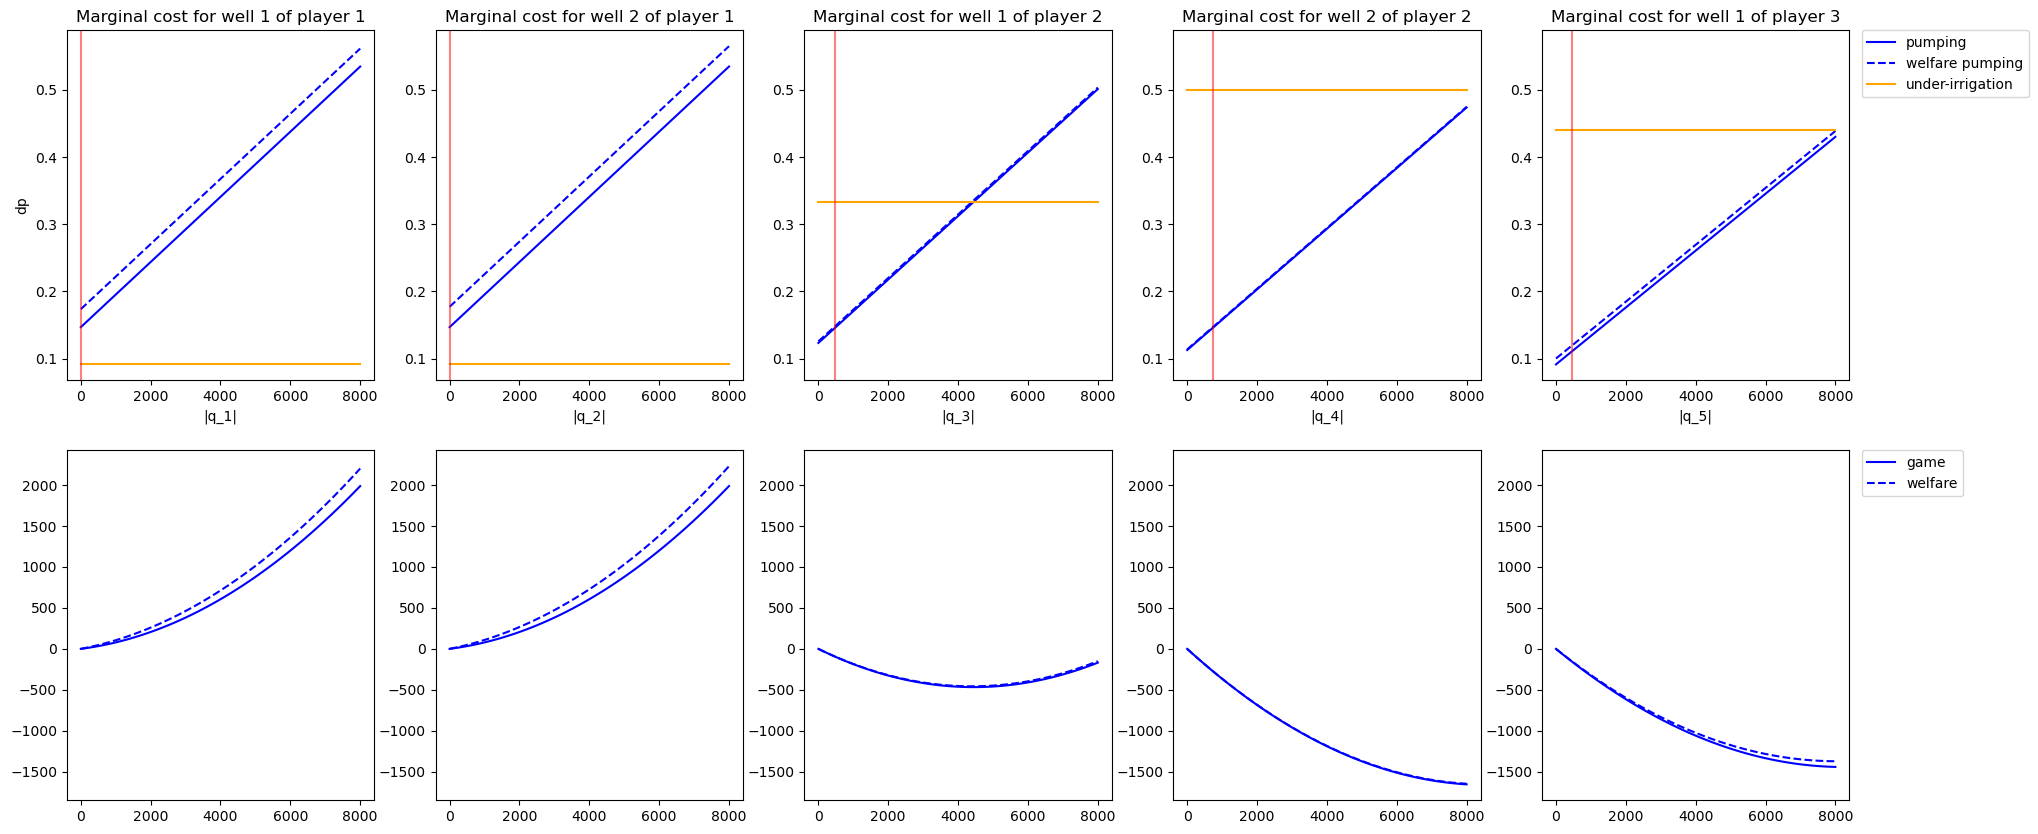

In [895]:
plot_marginal(-U_game[:4].sum(), -U_game[4:8].sum(), -U_game[8:12].sum(), -U_game[12:16].sum(), -U_game[16:].sum())

In [846]:
base_cost_model._get_water_requirement(0,1).reshape(-1,1)

array([[10500.],
       [    0.],
       [ 6000.],
       [    0.],
       [ 2800.],
       [  700.],
       [    0.],
       [    0.],
       [ 3150.],
       [ 3150.],
       [ 2250.],
       [ 1800.]])

# Coupled constraint

In [500]:
A_game = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0]) +\
                                  (base_model.B_v[v].T @ I_A_inv.T @ base_cost_model.Mp_v[v] + base_cost_model.Rp_v[v] + base_cost_model.Ri_v[v][0]).T,
                              axis=0) for v in range(base_model.n_agent)]).T
H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well))])
h = np.vstack([np.zeros((4*n_well, 1)), np.array([[10000, 100000, 100000, 10000, 200000]]).T, 10000.*np.ones((1,1))])
U_game, _, _, _ = fbrs(A_game+0*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_welfare, _, _, _ = fbrs((A_aggr+A_aggr.T), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_game.T, U_welfare.T

(array([[-2.71484162e+03, -5.16910219e-18,  9.56393104e-14, -4.30107499e-18, -2.71447489e+03, -7.15992227e-18,  9.57176271e-14, -4.88557579e-18, -6.17284850e+02, -1.57520751e-17, -1.39488692e-17, -1.39488692e-17, -1.23549927e+03, -1.58865741e-17, -1.49838086e-17, -1.59595949e-17, -1.59213862e+03, -1.31044519e-17,  1.04054714e-13, -1.12576075e+03]]),
 array([[-2.72279892e+03, -1.55980528e-17,  9.64356017e-14, -1.57051599e-17, -2.72341656e+03, -6.26812113e-18,  9.65387724e-14, -5.94079418e-18, -4.30586244e+02, -1.77987379e-17, -1.30270701e-17, -1.20512929e-17, -1.39933735e+03, -1.88311361e-17, -1.43897553e-17, -1.60224909e-17, -1.59629940e+03, -1.69822179e-17,  9.67127316e-14, -1.12756153e+03]]))

In [501]:
U_game.sum(), U_welfare.sum()

(np.float64(-10000.0), np.float64(-10000.000000000002))

In [507]:
U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()

(np.float64(-2714.8416166634097),
 np.float64(-2714.474894246684),
 np.float64(-617.284849591176),
 np.float64(-1235.4992684493204),
 np.float64(-2717.8993710494105))

In [508]:
U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum(), U_welfare[16:].sum()

(np.float64(-2722.798917467999),
 np.float64(-2723.4165552811264),
 np.float64(-430.5862443611316),
 np.float64(-1399.3373528563288),
 np.float64(-2723.8609300334165))

In [509]:
((U_game-U_welfare)[:4].sum()/(U_game)[:4].sum(), (U_game-U_welfare)[4:8].sum()/(U_game)[4:8].sum(), (U_game-U_welfare)[8:12].sum()/(U_game)[8:12].sum(), (U_game-U_welfare)[12:16].sum()/(U_game)[12:16].sum(), (U_game-U_welfare)[16:].sum()/(U_game)[16:].sum())

(np.float64(-0.0029310368441932133),
 np.float64(-0.0032940665811255834),
 np.float64(0.30245130000143977),
 np.float64(-0.1326088072983177),
 np.float64(-0.0021934436011530273))

In [506]:
U_game.T @ A_aggr @ U_game + B_aggr @ U_game , U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare

(array([[-500.19669122]]), array([[-500.33106884]]))

In [565]:
import itertools
diff = {}
for w_1, w_2, w_3, w_4, w_5 in itertools.product([100, 500, 1000, 2000, 5000, 10000], repeat=5):
    H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well))])
    h = np.vstack([np.zeros((4*n_well, 1)), np.array([[w_1, w_2, w_3, w_4, w_5]]).T, 100000.*np.ones((1,1))])
    U_game, _, _, _ = fbrs(A_game+1e-8*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
    U_welfare, _, _, _ = fbrs((A_aggr+A_aggr.T)+1e-8*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
    diff[w_1, w_2, w_3, w_4, w_5] = (((U_game.T @ A_aggr @ U_game + B_aggr @ U_game) - (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare)))/((U_game.T @ A_aggr @ U_game + B_aggr @ U_game))

In [568]:
min(diff, key=diff.get), diff[min(diff, key=diff.get)]

((10000, 10000, 2000, 5000, 100), array([[-0.00092516]]))

In [567]:
diff[(10000, 10000, 100, 2000, 2000)]

array([[-5.43352936e-06]])

In [570]:
H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well))])
h = np.vstack([np.zeros((4*n_well, 1)), np.array([[10000, 10000, 2000, 5000, 100]]).T, 100000.*np.ones((1,1))])
U_game, _, _, _ = fbrs(A_game+0*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_welfare, _, _, _ = fbrs((A_aggr+A_aggr.T)+0*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
((U_game.T @ A_aggr @ U_game + B_aggr @ U_game), (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare))

(array([[-1510.76528885]]), array([[-1512.16850199]]))

# Coupled constraints and heterogeneous cost parameters

In [1076]:
heterogenous_parameter_file = "/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/Setup/stable_model_parameters.json"

In [1094]:
# Example crop repartition
same_crops = np.array([[1., 1., 0.], [0., 0., 0.], [0., 0., 0.], [0., 0., 0.]])

In [1095]:
# Initialize System and Model
heterogenous_system = SimpleSquareExample(heterogenous_parameter_file, boundary_condition="Constant Head")
heterogenous_model = IrrigationSchedulingModel(heterogenous_parameter_file, boundary_condition="Constant Head")
heterogenous_cost_model = IrrigationSchedulingCost(heterogenous_parameter_file, base_model, same_crops)

In [1096]:
heterogenous_cost_model._compute_under_irrigation_cost_matrices(0,1)

In [1097]:
I_A_inv = np.linalg.inv(np.eye(heterogenous_model.A.shape[0]) - heterogenous_model.A)

In [1098]:
B_minus_v = [sp.hstack([heterogenous_model.B_v[mv] for mv in range(heterogenous_model.n_agent) if mv !=v]) for v in range(heterogenous_model.n_agent)]

In [1099]:
A_aggr = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (heterogenous_model.B_v[v].T @ I_A_inv.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Rp_v[v] + heterogenous_cost_model.Ri_v[v][0]),
                              axis=0) for v in range(heterogenous_model.n_agent)])
B_aggr = np.hstack([(heterogenous_model.C.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Lp_v[v] + heterogenous_cost_model.Li_v[v][0]) for v in range(heterogenous_model.n_agent)])
U_opt = - np.linalg.pinv(A_aggr + A_aggr.T) @ B_aggr.T
U_opt.T

array([[-17449.11502416,   5680.72022354,   5680.72022354,   5680.72022354, -17550.88497583,   5578.95027187,   5578.95027187,   5578.95027187,  -1735.46417619,   1307.87675188,   1307.87675188,   1307.87675188,  -1764.53582381,   1278.80510426,   1278.80510426,   1278.80510426,    480.84162107,    480.84162107,    480.84162107,    480.84162107]])

In [1100]:
A_game = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (heterogenous_model.B_v[v].T @ I_A_inv.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Rp_v[v] + heterogenous_cost_model.Ri_v[v][0]) +\
                                  (heterogenous_model.B_v[v].T @ I_A_inv.T @ heterogenous_cost_model.Mp_v[v] + heterogenous_cost_model.Rp_v[v] + heterogenous_cost_model.Ri_v[v][0]).T,
                              axis=0) for v in range(heterogenous_model.n_agent)]).T
H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well))])
h = np.vstack([np.zeros((4*n_well, 1)), np.array([[10000, 100000, 100000, 10000, 200000]]).T, 1000000.*np.ones((1,1))])
U_game, _, _, _ = fbrs(A_game+0*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_welfare, _, _, _ = fbrs((A_aggr+A_aggr.T), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_game.T, U_welfare.T

(array([[-7.72753970e+03, -8.24667299e-16, -8.24633339e-16, -8.24682520e-16, -7.68724995e+03, -8.25342740e-16, -8.25339352e-16, -8.25347822e-16, -1.16896235e+03,  4.59903766e-18,  4.59903766e-18,  4.97173144e-18, -2.32298882e+03,  2.58582688e-17,  2.58307474e-17,  2.58307474e-17, -3.97944598e-16, -3.97802300e-16, -3.97809073e-16, -3.97802300e-16]]),
 array([[-7.24396941e+03, -7.65895678e-16, -7.65985490e-16, -7.65900760e-16, -6.80080538e+03, -7.73942983e-16, -7.73873263e-16, -7.73945524e-16, -1.16836750e+03,  6.04209653e-18,  6.04209653e-18,  5.98132192e-18, -2.32358365e+03,  2.67083096e-17,  2.67019567e-17,  2.67290617e-17, -3.83043186e-16, -3.82900885e-16, -3.82873780e-16, -3.82900885e-16]]))

In [1101]:
U_game.T @ A_aggr @ U_game + B_aggr @ U_game , U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare

(array([[-1600.34005359]]), array([[-1600.39041428]]))

In [1102]:
(U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()), \
(U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum(), U_welfare[16:].sum()), \
((U_game-U_welfare)[:4].sum()/(U_game)[:4].sum(), (U_game-U_welfare)[4:8].sum()/(U_game)[4:8].sum(), (U_game-U_welfare)[8:12].sum()/(U_game)[8:12].sum(), (U_game-U_welfare)[12:16].sum()/(U_game)[12:16].sum(), (U_game-U_welfare)[16:].sum()/(U_game)[16:].sum())

((np.float64(-7727.539704319232),
  np.float64(-7687.249952693332),
  np.float64(-1168.962346130285),
  np.float64(-2322.9888189268495),
  np.float64(-1.5913582708393663e-15)),
 (np.float64(-7243.969406659542),
  np.float64(-6800.805379664198),
  np.float64(-1168.3674975501656),
  np.float64(-2323.5836516648583),
  np.float64(-1.5317187364442921e-15)),
 (np.float64(0.06257752352788346),
  np.float64(0.11531361390409268),
  np.float64(0.0005088688973502957),
  np.float64(-0.0002560635389900779),
  np.float64(0.03747712597969356)))

In [1103]:
(U_game[:8,:].T @ A_aggr[:8,:] @ U_game + B_aggr[:,:8] @ U_game[:8,:] , U_welfare[:8,:].T @ A_aggr[:8,:] @ U_welfare + B_aggr[:,:8] @ U_welfare[:8,:]), (U_game[8:16,:].T @ A_aggr[8:16,:] @ U_game + B_aggr[:,8:16] @ U_game[8:16,:] , U_welfare[8:16,:].T @ A_aggr[8:16,:] @ U_welfare + B_aggr[:,8:16] @ U_welfare[8:16,:]), (U_game[16:,:].T @ A_aggr[16:,:] @ U_game + B_aggr[:,16:] @ U_game[16:,:] , U_welfare[16:,:].T @ A_aggr[16:,:] @ U_welfare + B_aggr[:,16:] @ U_welfare[16:,:])

((array([[-5.22560378]]), array([[-5.26605097]])),
 (array([[-1595.11444982]]), array([[-1595.12436331]])),
 (array([[1.29362411e-18]]), array([[1.24322564e-18]])))

# Crop choice

In [510]:
# Every one has access to all crops
all_crops = np.ones((4,3))
all_system = SimpleSquareExample(base_parameter_file, boundary_condition="Constant Head")
all_model = IrrigationSchedulingModel(base_parameter_file, boundary_condition="Constant Head")
all_cost_model = IrrigationSchedulingCost(base_parameter_file, all_model, all_crops)
# Simulate constant 
with open("Components/Setup/simple_demand.json", 'r') as file:
    params = json.load(file)
    all_cost_model.yield_sensitivity = np.array(params['costs']['yield_sensitivity'])  # [n_crops, n_agent]
    all_cost_model.ET0 = params['physical']['ET0']
    # Time-varying utility data
    all_cost_model._construct_crop_yield_data(params['crops'])
    all_cost_model._construct_evapotranspiration_data(params['crops'])
    all_cost_model._construct_available_water(params['rain'])
all_cost_model._compute_under_irrigation_cost_matrices(0,1)

In [512]:
I_A_inv = np.linalg.inv(np.eye(all_model.A.shape[0]) - all_model.A)
B_minus_v = [sp.hstack([all_model.B_v[mv] for mv in range(all_model.n_agent) if mv !=v]) for v in range(all_model.n_agent)]


A_aggr = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ all_cost_model.Mp_v[v] + all_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (all_model.B_v[v].T @ I_A_inv.T @ all_cost_model.Mp_v[v] + all_cost_model.Rp_v[v] + all_cost_model.Ri_v[v][0]),
                              axis=0) for v in range(all_model.n_agent)])
B_aggr = np.hstack([(all_model.C.T @ all_cost_model.Mp_v[v] + all_cost_model.Lp_v[v] + all_cost_model.Li_v[v][0]) for v in range(all_model.n_agent)])

A_game = np.hstack([np.insert((B_minus_v[v].T @ I_A_inv.T @ all_cost_model.Mp_v[v] + all_cost_model.Rp_v_minus[v]),
                              [4*np.cumsum([0]+n_well_per_player)[v]],
                              (all_model.B_v[v].T @ I_A_inv.T @ all_cost_model.Mp_v[v] + all_cost_model.Rp_v[v] + all_cost_model.Ri_v[v][0]) +\
                                  (all_model.B_v[v].T @ I_A_inv.T @ all_cost_model.Mp_v[v] + all_cost_model.Rp_v[v] + all_cost_model.Ri_v[v][0]).T,
                              axis=0) for v in range(all_model.n_agent)]).T

H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well))])
h = np.vstack([np.zeros((4*n_well, 1)), np.array([[50000, 50000, 100000, 10000, 20000]]).T, 800000.*np.ones((1,1))])

U_game, _, _, e_g = fbrs(A_game+1e-15*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_welfare, _, _, e_w = fbrs((A_aggr+A_aggr.T), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1, 1)))
U_game.T, U_welfare.T

(array([[-7.24858144e+03, -6.42567974e-18,  1.40302434e-14, -6.42567953e-18, -7.29180505e+03, -4.20410808e-18,  1.40316614e-14, -8.97417867e-18, -1.06121298e+03, -2.56639857e+02, -1.64495038e-17, -1.63952774e-17, -1.71651390e+03, -9.32086166e+02, -1.78965541e-17, -1.74630643e-17, -8.06601914e+03,  1.62678618e-13,  1.25318382e-13, -3.44657802e+03]]),
 array([[-7.15278513e+03, -1.69843277e-13, -1.69948692e-13, -1.69843366e-13, -7.24892700e+03, -1.69846519e-13, -1.69948489e-13, -1.69847061e-13, -6.09615060e+02, -3.39851791e-12, -1.92787128e-12, -1.92787123e-12, -2.06451190e+03, -8.57206274e+02,  1.46641727e-12,  1.46641836e-12, -8.00865006e+03, -5.69563488e-14, -5.69584756e-14, -3.42174880e+03]]))

In [513]:
e_g['eflag'], e_w['eflag']

(0, 0)

In [515]:
(U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()), (U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum(), U_welfare[16:].sum())

((np.float64(-7248.5814351649815),
  np.float64(-7291.805048101011),
  np.float64(-1317.8528360002554),
  np.float64(-2648.600069021897),
  np.float64(-11512.59715806754)),
 (np.float64(-7152.785126074298),
  np.float64(-7248.927002121498),
  np.float64(-609.6150595642753),
  np.float64(-2921.7181749783513),
  np.float64(-11430.398866201174)))

In [517]:
U_game.T @ A_aggr @ U_game + B_aggr @ U_game , U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare

(array([[-2873.23792971]]), array([[-2875.56678672]]))

In [518]:
U_game[4:16,:].T @ A_game[4:16,:] @ U_game + B_aggr[:,4:16] @ U_game[4:16,:]

array([[-6.05218702e-08]])

In [519]:
U_test = U_game.copy()
U_test[5,:] -= 100
U_test[4:16,:].T @ A_game[4:16,:] @ U_test + B_aggr[:,4:16] @ U_test[4:16,:]

array([[9.59247418]])

In [521]:
(sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]])) @ U_game

array([[-1.45403865e+04],
       [-1.06297878e-17],
       [ 2.80619048e-14],
       [-1.53998582e-17],
       [-2.77772688e+03],
       [-1.18872602e+03],
       [-3.43460579e-17],
       [-3.38583417e-17],
       [-8.06601914e+03],
       [ 1.62678618e-13],
       [ 1.25318382e-13],
       [-3.44657802e+03]])

In [524]:
np.kron(np.eye(3), np.ones((1,4))) @ (sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]]) / -all_cost_model._get_water_requirement(0,1).reshape(-1,1))

array([[-4.76190476e-05, -4.76190476e-05, -6.66666667e-05, -1.11111111e-04, -4.76190476e-05, -4.76190476e-05, -6.66666667e-05, -1.11111111e-04,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -2.85714286e-04, -2.85714286e-04, -4.00000000e-04, -6.66666667e-04, -2.85714286e-04, -2.85714286e-04, -4.00000000e-04, -6.66666667e-04,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00, -9.52380952e-05, -9.52

In [525]:
np.kron(np.eye(3), np.ones((1,4))) @ (sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]]) / -all_cost_model._get_water_requirement(0,1).reshape(-1,1)) @ U_game

array([[0.69239936],
       [1.13327226],
       [1.53409853]])

In [526]:
((sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]]) / -all_cost_model._get_water_requirement(0,1).reshape(-1,1)) @ U_game)[8:12].sum()

np.float64(1.534098525614491)

In [528]:
H = np.vstack([np.eye(4*n_well), -np.kron(np.eye(n_well), np.ones((1,4))), -np.ones((1,4*n_well)), \
    np.kron(np.eye(3), np.ones((1,4))) @ (sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]]) / -all_cost_model._get_water_requirement(0,1).reshape(-1,1))])
h = np.vstack([np.zeros((4*n_well, 1)), np.array([[50000, 50000, 100000, 10000, 20000]]).T, 800000.*np.ones((1,1)), np.ones((3,1))])

U_game, _, _, e_g = fbrs(A_game+1e-15*np.eye(4*n_well), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1+3, 1)))
U_welfare, _, _, e_w = fbrs((A_aggr+A_aggr.T), B_aggr.T, H, h, np.zeros((4*n_well, 1)), np.zeros((4*n_well+ n_well +1+3, 1)))
e_g['eflag'], e_w['eflag']

(0, 0)

In [536]:
(U_game[:4].sum(), U_game[4:8].sum(), U_game[8:12].sum(), U_game[12:16].sum(), U_game[16:].sum()), (U_welfare[:4].sum(), U_welfare[4:8].sum(), U_welfare[8:12].sum(), U_welfare[12:16].sum(), U_welfare[16:].sum())

((np.float64(-7278.000366090613),
  np.float64(-7301.804875535074),
  np.float64(-1119.359693977634),
  np.float64(-2380.640306766594),
  np.float64(-8283.223446467084)),
 (np.float64(-7204.448268585935),
  np.float64(-7253.107002361447),
  np.float64(-648.8011601539173),
  np.float64(-2851.198839849047),
  np.float64(-8266.9795019213)))

In [537]:
((U_game-U_welfare)[:4].sum()/(U_game)[:4].sum(), (U_game-U_welfare)[4:8].sum()/(U_game)[4:8].sum(), (U_game-U_welfare)[8:12].sum()/(U_game)[8:12].sum(), (U_game-U_welfare)[12:16].sum()/(U_game)[12:16].sum(), (U_game-U_welfare)[16:].sum()/(U_game)[16:].sum())

(np.float64(0.010106085985838852),
 np.float64(0.006669292593231423),
 np.float64(0.4203818811374128),
 np.float64(-0.19766049148414594),
 np.float64(0.001961065598527507))

In [538]:
U_game.T @ A_aggr @ U_game + B_aggr @ U_game , U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare

(array([[-2742.95413232]]), array([[-2743.97598644]]))

In [539]:
np.kron(np.eye(3), np.ones((1,4))) @ (sp.block_array([[sp.eye(4), sp.eye(4), None, None, None], [None, None, sp.eye(4), sp.eye(4), None], [None, None, None, None, sp.eye(4)]]) / -all_cost_model._get_water_requirement(0,1).reshape(-1,1)) @ U_game

array([[0.69427644],
       [1.        ],
       [1.        ]])

In [540]:
(all_cost_model._get_water_requirement(0,1).reshape(-1,1)*all_cost_model._get_under_irrigation_weight(0,1).reshape(-1,1)).T @ all_cost_model._get_water_requirement(0,1).reshape(-1,1)

array([[4890.375]])

In [541]:
((U_game.T @ A_aggr @ U_game + B_aggr @ U_game) - (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare))/(U_game.T @ A_aggr @ U_game + B_aggr @ U_game)

array([[-0.00037254]])

In [542]:
((U_game.T @ A_aggr @ U_game + B_aggr @ U_game) - (U_welfare.T @ A_aggr @ U_welfare + B_aggr @ U_welfare))/(U_game.T @ A_aggr @ U_game + B_aggr @ U_game + (all_cost_model._get_water_requirement(0,1).reshape(-1,1)*all_cost_model._get_under_irrigation_weight(0,1).reshape(-1,1)).T @ all_cost_model._get_water_requirement(0,1).reshape(-1,1))

array([[0.00047585]])

In [543]:
(U_game[:8,:].T @ A_aggr[:8,:] @ U_game + B_aggr[:,:8] @ U_game[:8,:] , U_welfare[:8,:].T @ A_aggr[:8,:] @ U_welfare + B_aggr[:,:8] @ U_welfare[:8,:]), (U_game[8:16,:].T @ A_aggr[8:16,:] @ U_game + B_aggr[:,8:16] @ U_game[8:16,:] , U_welfare[8:16,:].T @ A_aggr[8:16,:] @ U_welfare + B_aggr[:,8:16] @ U_welfare[8:16,:]), (U_game[16:,:].T @ A_aggr[16:,:] @ U_game + B_aggr[:,16:] @ U_game[16:,:] , U_welfare[16:,:].T @ A_aggr[16:,:] @ U_welfare + B_aggr[:,16:] @ U_welfare[16:,:])

((array([[-1301.58636531]]), array([[-1302.997631]])),
 (array([[-170.6582007]]), array([[-169.87959627]])),
 (array([[-1270.70956631]]), array([[-1271.09875917]])))

What if instead of cost, we use yield revenue to compute the economic cost and the difference between welfare and game?

# Higher heterogeneity

## Pumping weight difference (Electricity)

##### Similar electricity prices

In [923]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-120244/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-120118/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


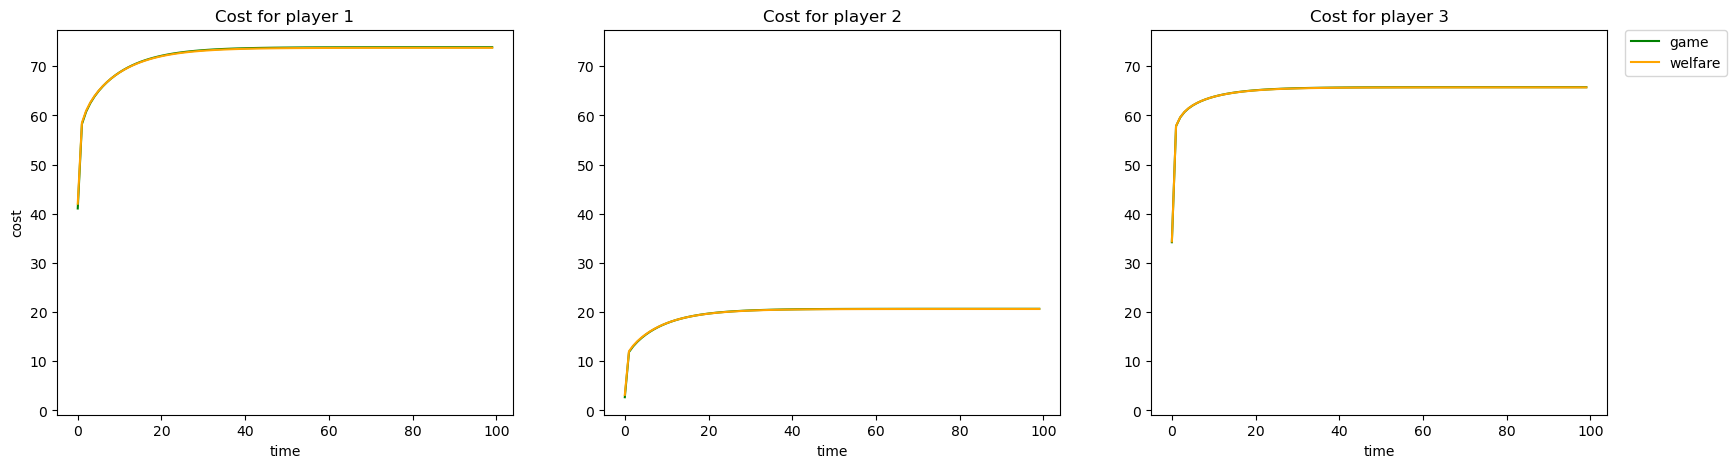

In [924]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


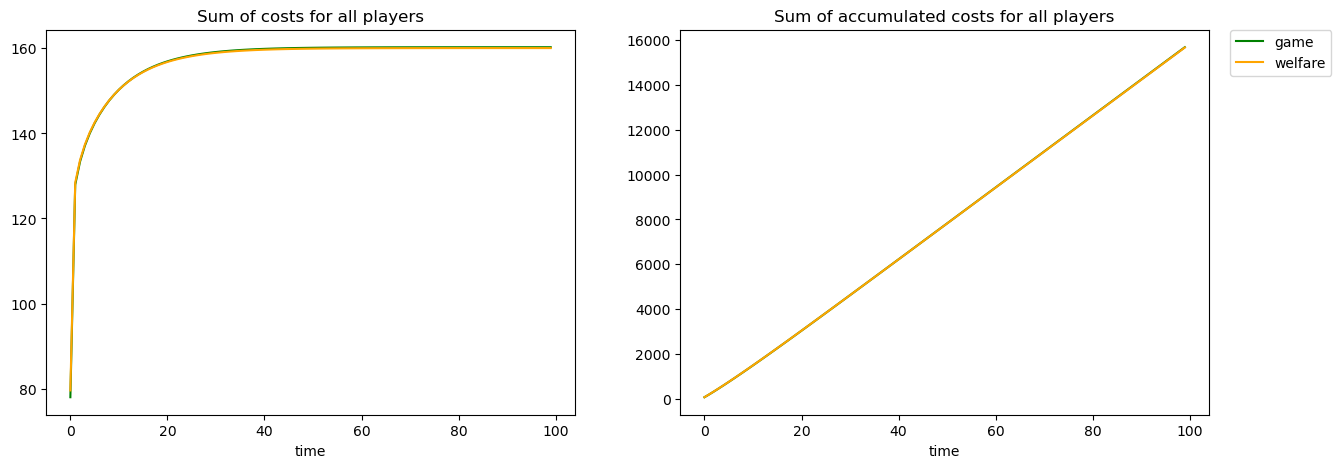

In [926]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

##### Electricity prices 5x higher for player 2

In [929]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-120800/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-121023/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


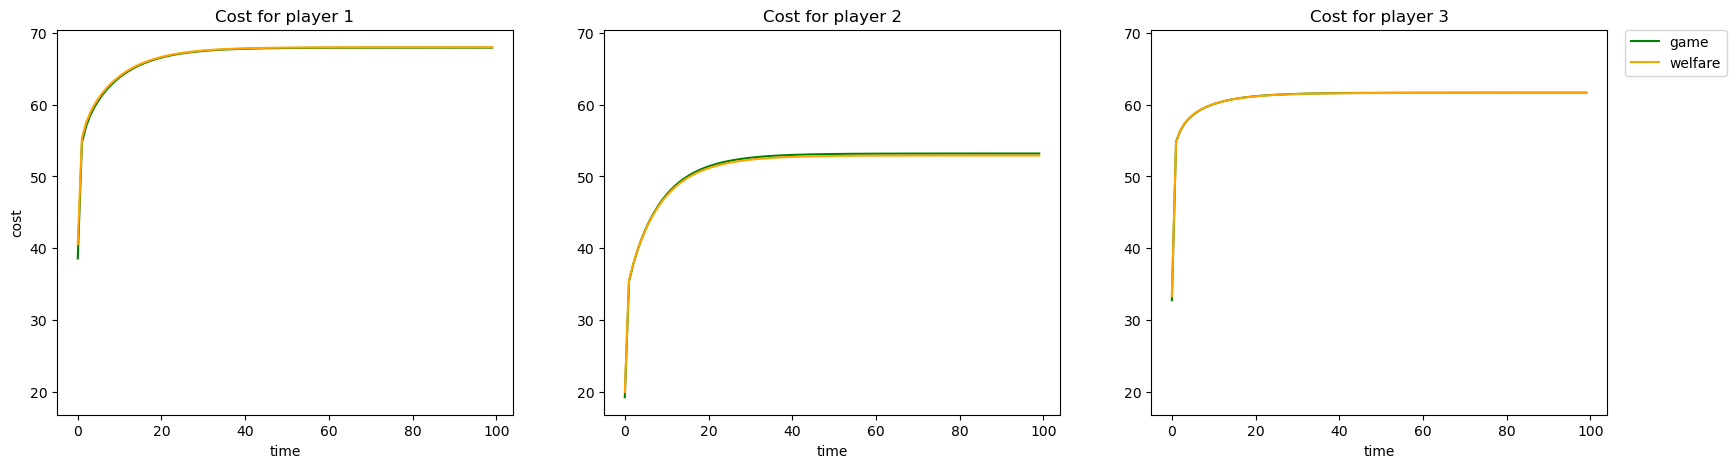

In [930]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


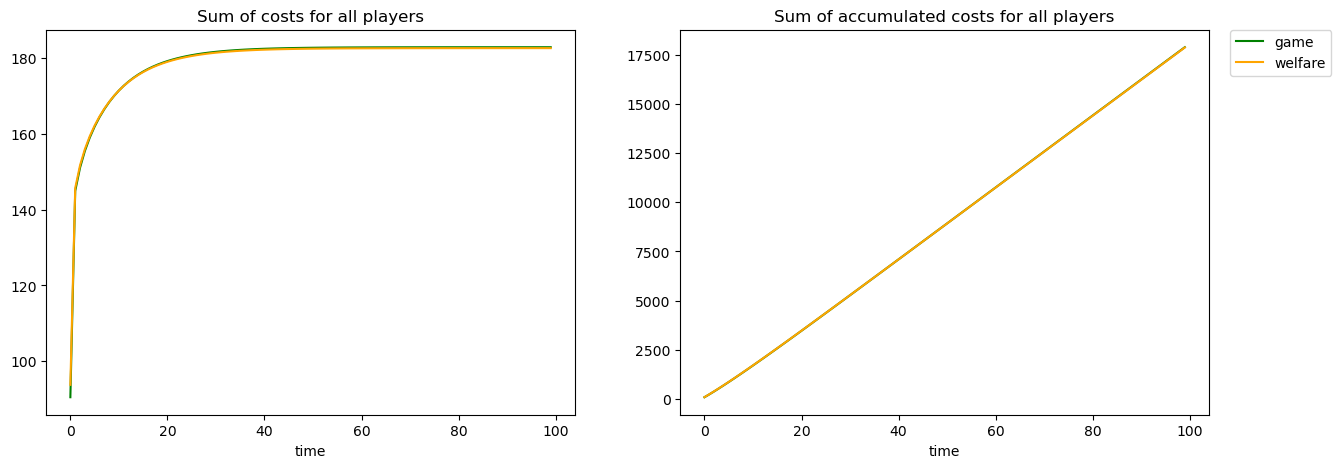

In [931]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

##### Electricity prices 5x higher for player 1

In [935]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-121731/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-121400/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


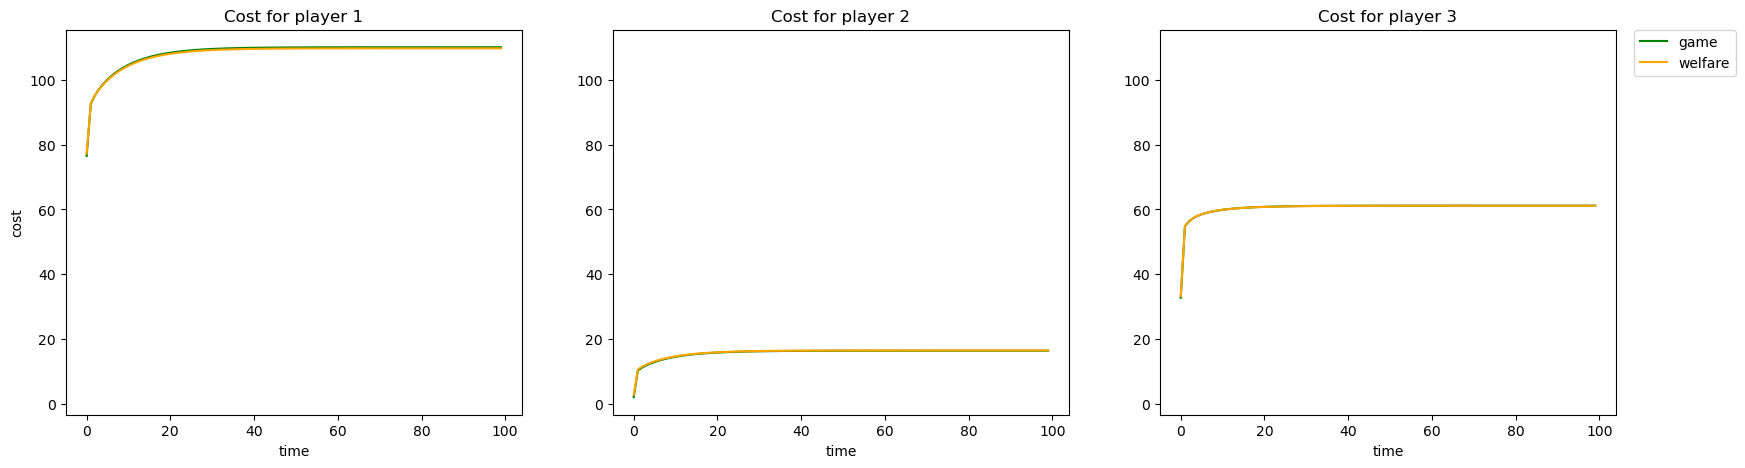

In [936]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


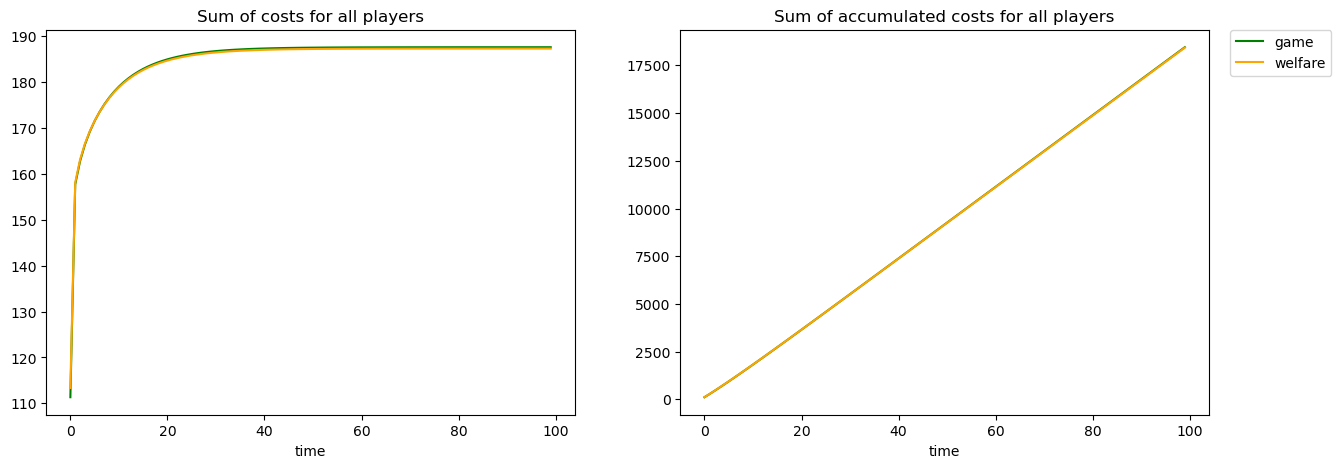

In [937]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

##### Electricity prices 100x higher for player 1

In [939]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122026/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122153/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


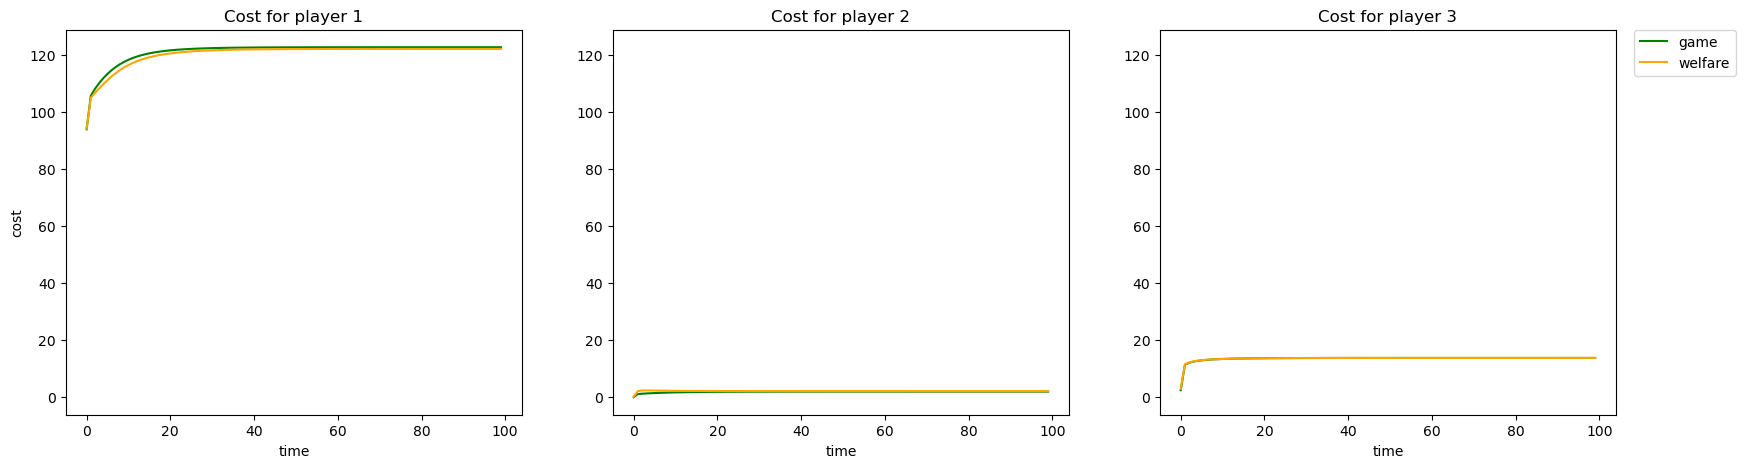

In [940]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


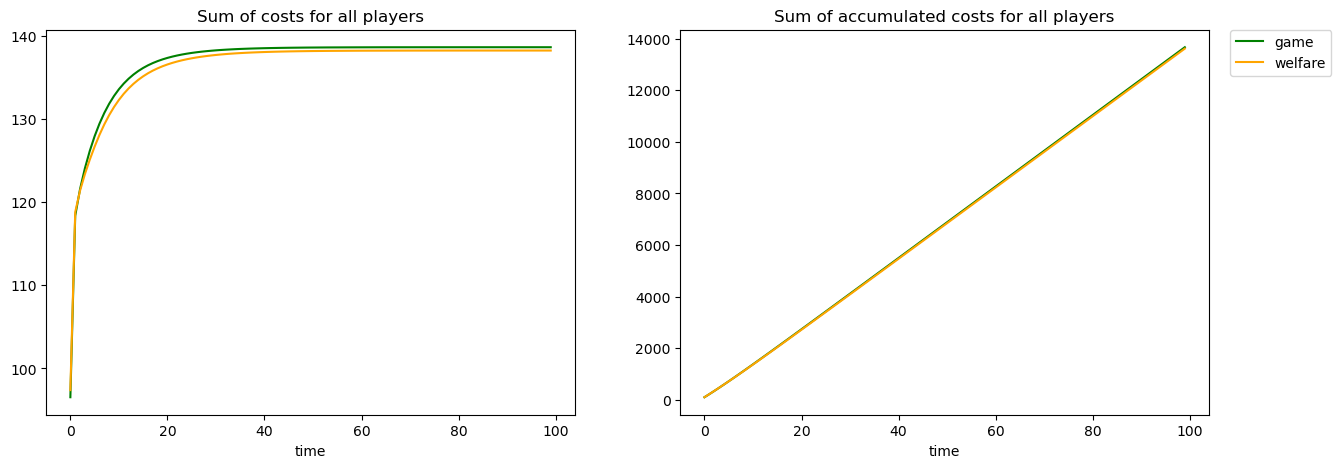

In [941]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

##### Electricity prices 100x higher for player 2

In [942]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122648/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-122441/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


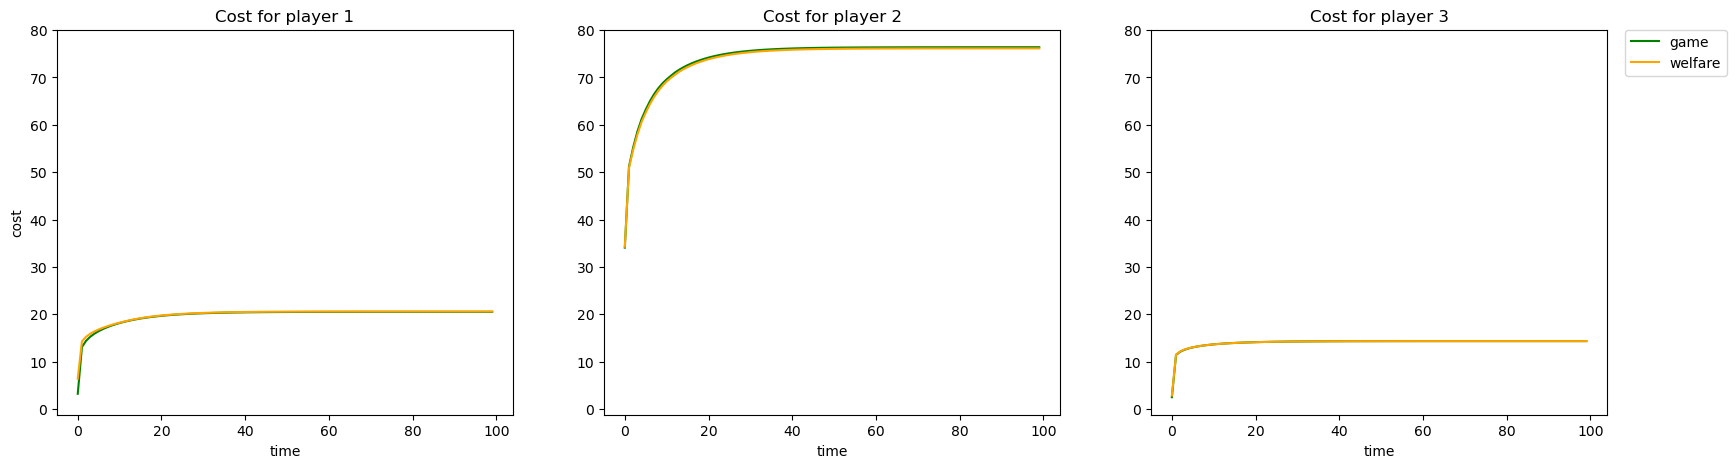

In [943]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


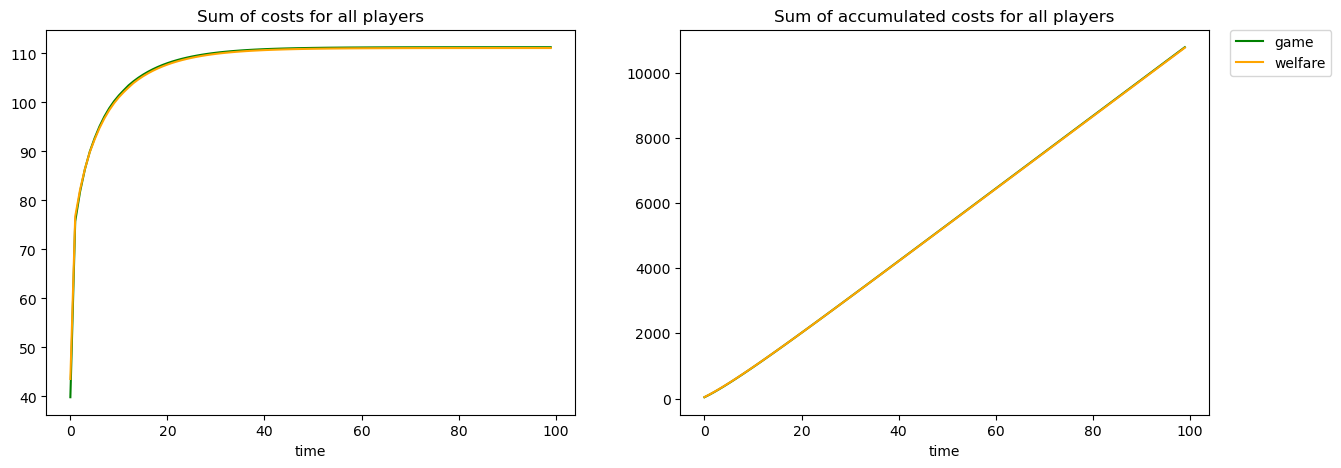

In [944]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

#### Electricity price 100x higher for player 2 who is also very sensible to yield

Player 1: small electricity prices, little sensibility to yield and high demand

Player 2: high sensibility, high demand

In [951]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144301/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144404/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


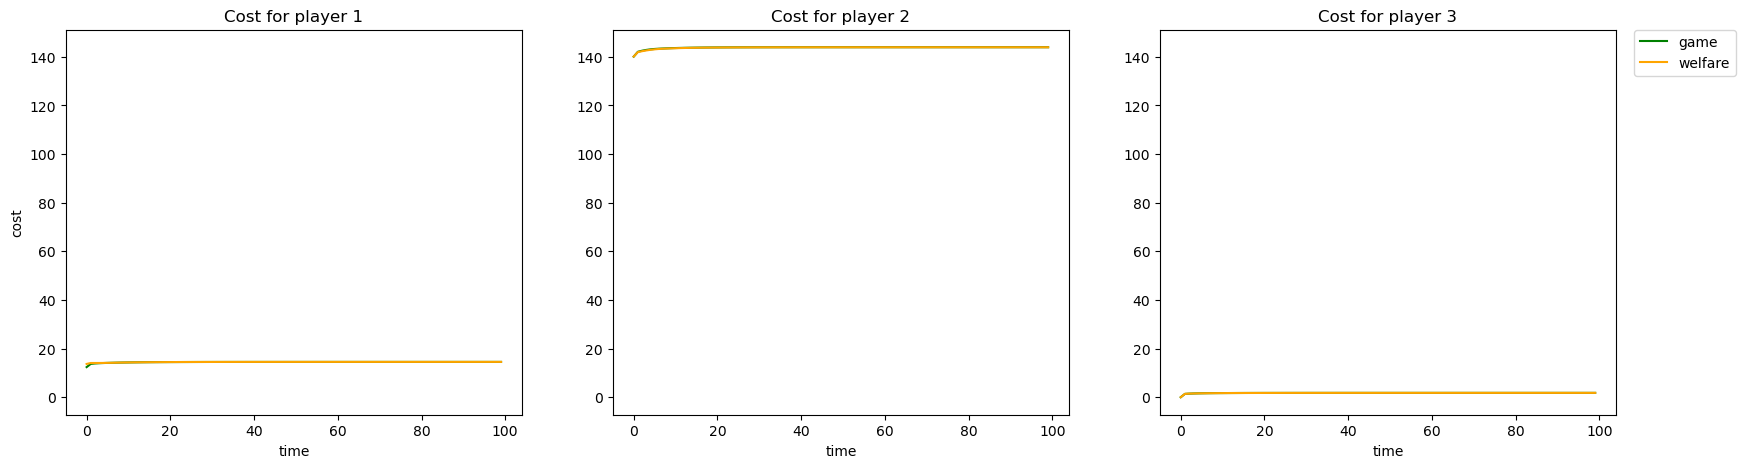

In [952]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


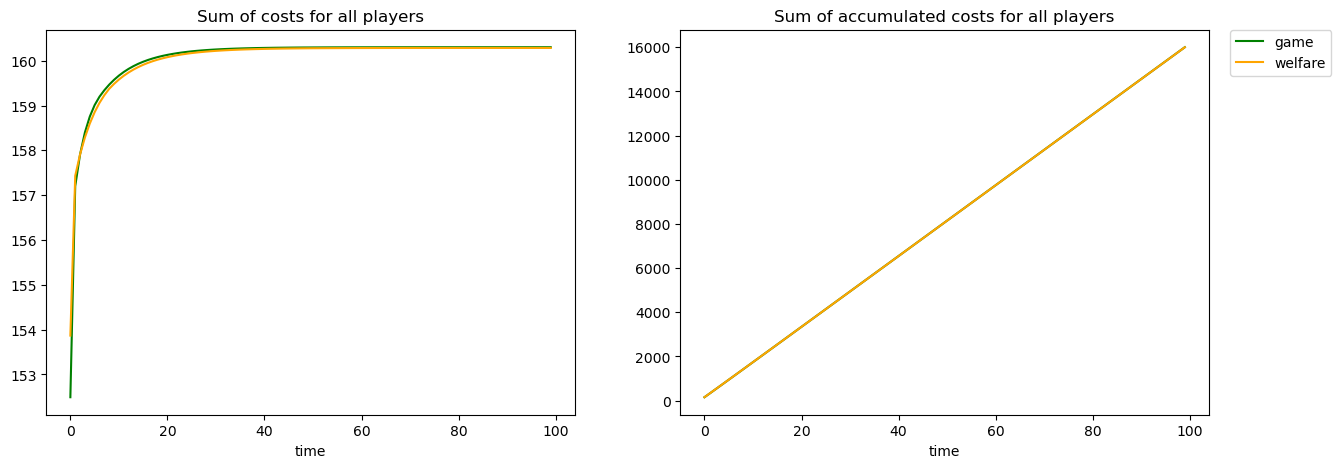

In [953]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

#### Electricity price 100x higher for player 2 who is also very sensible to yield and has less land

Player 1: small electricity prices, little sensibility to yield and high demand

Player 2: high sensibility, lower demand

In [973]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144748/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-144617/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


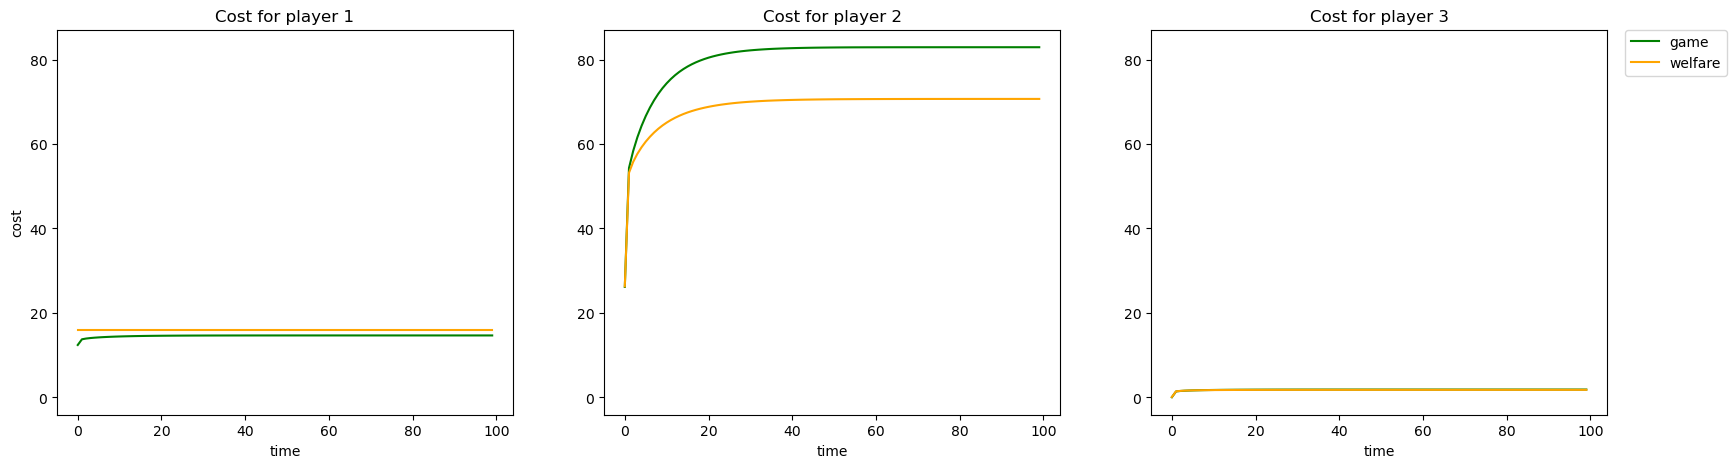

In [974]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


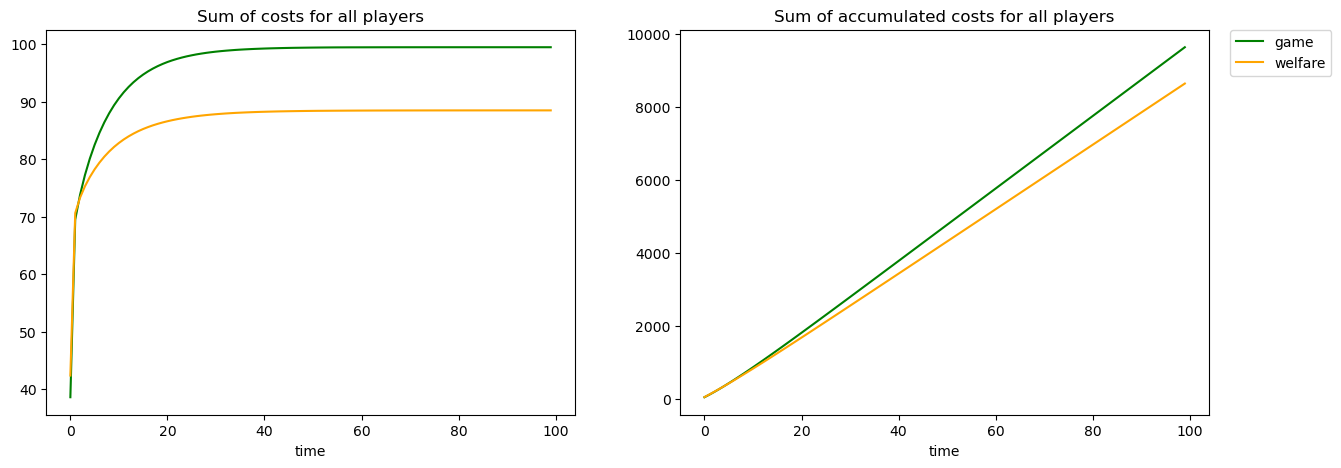

In [975]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [976]:
np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1], (np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1])/np.cumsum(data_wf['model_profit'].sum(axis=0))[-1]

(np.float64(996.9717266792177), np.float64(-0.11528741990864301))

#### Effect amplification

Increase yield sensitivity of player 2

In [999]:
data_si = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-150617/result_data.npz')
data_wf = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250715-150456/result_data.npz')

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3210852428.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


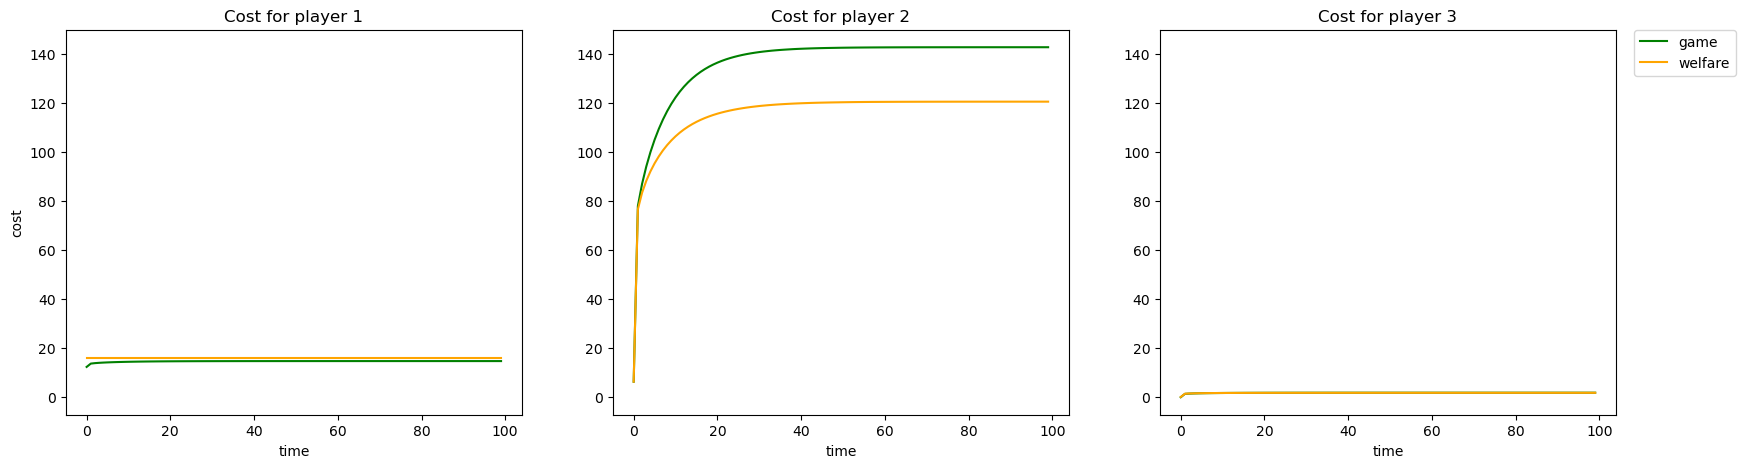

In [1000]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-data_si['model_profit'][ii, :], 'g', label='game')
    ax.plot(-data_wf['model_profit'][ii, :], color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_29045/3247981124.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


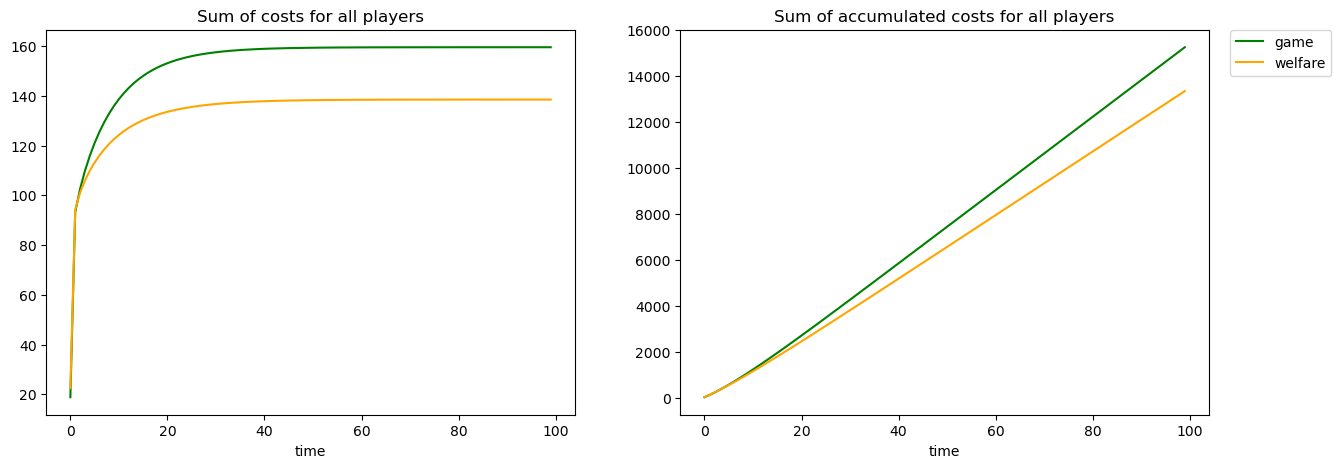

In [1001]:
# Plot total cost
fig = plt.figure(figsize=(10+5,5))
ax = fig.add_subplot(1, 2, 1)
ttl = f"Sum of costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-data_si['model_profit'].sum(axis=0), 'g')
ax.plot(-data_wf['model_profit'].sum(axis=0), color="orange")
ax = fig.add_subplot(1, 2, 2)
ttl = f"Sum of accumulated costs for all players"
ax.set_title(ttl)
ax.set_xlabel("time")
if ii == 0:
    ax.set_ylabel("cost")
ax.plot(-np.cumsum(data_si['model_profit'].sum(axis=0)), 'g', label='game')
ax.plot(-np.cumsum(data_wf['model_profit'].sum(axis=0)), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [993]:
np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1], (np.cumsum(data_wf['model_profit'].sum(axis=0))[-1] - np.cumsum(data_si['model_profit'].sum(axis=0))[-1])/np.cumsum(data_wf['model_profit'].sum(axis=0))[-1]

(np.float64(1909.683953077676), np.float64(-0.1430653317060164))

In [994]:
data_wf['model_profit'].sum(axis=0)[-1] - data_si['model_profit'].sum(axis=0)[-1], (data_wf['model_profit'].sum(axis=0)[-1] - data_si['model_profit'].sum(axis=0)[-1])/data_wf['model_profit'].sum(axis=0)[-1]

(np.float64(21.046261763382688), np.float64(-0.15193471804963676))

In [995]:
[data_wf['model_profit'][ii,-1] - data_si['model_profit'][ii,-1] for ii in range(3)], [(data_wf['model_profit'][ii,-1] - data_si['model_profit'][ii,-1])/data_wf['model_profit'][ii,-1] for ii in range(3)]

([np.float64(-1.207270759439167),
  np.float64(22.213349954953742),
  np.float64(0.04018256786814334)],
 [np.float64(0.07545442246494799),
  np.float64(-0.18407548219099937),
  np.float64(-0.021761263303116493)])

Looking at the equation we realize that:
- the elements of the linear part of the under-irrigation cost are proportional with the yield sensitivity and inversely proportional with the land size
- the elements of the quadratic part of the under-irrigation cost are proportional with yield sensitivity and inversely proportional with the square of the land size

So:
- increasing land size increase the zero-crossing of the gradient and decrease it's slope
- increasing yield sensitivity increase slope without changing zero-crossing

This means that, if we don't change the pumping cost, the same optimal pumping rate with decreased sensibility can be obtained by increasing land size and increasing yield sensitivity. The under-irrigation gradient slope will be smaller iff $\left(\frac{Land'}{Land}\right)^2 \ge \frac{Sensitivity'}{Sensitivity}$.